### EDA và xây dựng Cleaned Dataset không rò rỉ cho dự án Spring XD (TAWOS v1.1)

Notebook thực hiện kiểm toán dữ liệu, xử lý lỗi định dạng, tái dựng trạng thái lịch sử tại thời điểm ước lượng (Real_Estimation_Date) và xuất bộ dữ liệu sạch (cleaned_dataset) không bị rò rỉ thời gian cho dự án Spring XD từ C:/tawos/tawos_eda.db.

### 1. Kết nối CSDL C:/tawos/tawos_eda.db và tải dữ liệu dự án Spring XD

Kết nối CSDL ở chế độ chỉ đọc (read-only) và trích xuất toàn bộ bảng Issue, Change_Log, Component và Issue_Component của dự án Spring XD (Project_Key = 'XD', Project_ID = 1).

In [1]:
import os
import re
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (14, 4.5)
plt.rcParams['font.size'] = 11

db_path = "C:/tawos/tawos_eda.db"
conn = sqlite3.connect(f"file:{db_path}?mode=ro", uri=True)

df_proj = pd.read_sql("SELECT ID, Project_Key, Name, Start_Date, Last_Update_Date, SP_Field_ID FROM Project WHERE Project_Key = 'XD';", conn)
project_id = int(df_proj['ID'].iloc[0])
display(df_proj)

df_xd_all = pd.read_sql(f"SELECT * FROM Issue WHERE Project_ID = {project_id};", conn)
min_id, max_id = int(df_xd_all['ID'].min()), int(df_xd_all['ID'].max())

df_cl_all = pd.read_sql(f"SELECT * FROM Change_Log WHERE Issue_ID BETWEEN {min_id} AND {max_id};", conn)
df_cl_all = df_cl_all[df_cl_all['Issue_ID'].isin(df_xd_all['ID'])].copy()

df_comp = pd.read_sql(
    f"SELECT ic.Issue_ID, c.Name AS Component_Name FROM Issue_Component ic JOIN Component c ON ic.Component_ID = c.ID WHERE c.Project_ID = {project_id};",
    conn
)

print(f"Tổng số Issue của Spring XD: {len(df_xd_all):,} | Tổng số Change_Log: {len(df_cl_all):,} | Tổng liên kết Component: {len(df_comp):,}")

,ID,Project_Key,Name,Start_Date,Last_Update_Date,SP_Field_ID
0,1,XD,Spring XD,2013-04-12 06:37:17,2018-11-20 15:18:11,customfield_10142


Tổng số Issue của Spring XD: 3,707 | Tổng số Change_Log: 43,227 | Tổng liên kết Component: 1,375


### 2. Kiểm tra độ phủ Story Point và làm sạch ký tự bọc chuỗi từ SQL Dump

Lọc 3,542 công việc có Story_Point > 0 và loại bỏ các ký tự nháy kép dư thừa (\" và \"\"\") sinh ra khi import SQL ở cột Title, Description và Description_Text để đồng nhất định dạng với bảng Change_Log.

In [2]:
def strip_sql_quotes(val):
    if pd.isna(val):
        return ""
    s = str(val).strip()
    while len(s) >= 2:
        if s.startswith('\\"\\"\\"') and s.endswith('\\"\\"\\"') and len(s) >= 6:
            s = s[6:-6].strip()
        elif s.startswith('"""') and s.endswith('"""') and len(s) >= 6:
            s = s[3:-3].strip()
        elif s.startswith('\\"') and s.endswith('\\"') and len(s) >= 4:
            s = s[2:-2].strip()
        elif s.startswith('"') and s.endswith('"') and len(s) >= 2:
            s = s[1:-1].strip()
        else:
            break
    return s

valid_mask = df_xd_all['Story_Point'].notna() & (df_xd_all['Story_Point'] > 0)
df_xd = df_xd_all[valid_mask].copy().reset_index(drop=True)
df_cl = df_cl_all[df_cl_all['Issue_ID'].isin(df_xd['ID'])].copy().reset_index(drop=True)

print("Ví dụ Title và Description_Text TRƯỚC khi làm sạch ký tự bọc SQL:")
print(" - Raw Title:", repr(df_xd['Title'].iloc[0]))
print(" - Raw Desc :", repr(str(df_xd['Description_Text'].iloc[0])[:70]))

df_xd['Final_Title_Clean'] = df_xd['Title'].apply(strip_sql_quotes)
df_xd['Final_Desc_Clean'] = df_xd['Description_Text'].apply(strip_sql_quotes)

print("\nVí dụ Title và Description_Text SAU khi làm sạch:")
print(" - Clean Title:", repr(df_xd['Final_Title_Clean'].iloc[0]))
print(" - Clean Desc :", repr(df_xd['Final_Desc_Clean'].iloc[0][:70]))

cov_summary = pd.DataFrame({
    'Phân nhóm Issue (Spring XD)': ['Có Story_Point > 0', 'Có Story_Point = 0', 'Story_Point là NULL', 'Tổng cộng'],
    'Số lượng': [
        int(valid_mask.sum()),
        int((df_xd_all['Story_Point'] == 0).sum()),
        int(df_xd_all['Story_Point'].isna().sum()),
        len(df_xd_all)
    ],
    'Tỷ lệ (%)': [
        round(valid_mask.mean()*100, 2),
        round((df_xd_all['Story_Point'] == 0).mean()*100, 2),
        round(df_xd_all['Story_Point'].isna().mean()*100, 2),
        100.0
    ]
})
display(cov_summary)

Ví dụ Title và Description_Text TRƯỚC khi làm sạch ký tự bọc SQL:
 - Raw Title: '\\"How do I make a job restartable in spring xd\\"'
 - Raw Desc : '\\"\\"\\"The jobs that appear under Executions section of Jobs in spring '

Ví dụ Title và Description_Text SAU khi làm sạch:
 - Clean Title: 'How do I make a job restartable in spring xd'
 - Clean Desc : 'The jobs that appear under Executions section of Jobs in spring xd adm'


,Phân nhóm Issue (Spring XD),Số lượng,Tỷ lệ (%)
0,Có Story_Point > 0,3542,95.55
1,Có Story_Point = 0,163,4.40
2,Story_Point là NULL,2,0.05
3,Tổng cộng,3707,100.00


### 3. Kiểm tra dữ liệu khuyết và phân phối nhãn Story Point

Thống kê tỷ lệ khuyết dữ liệu trên 30 cột của bảng Issue và kiểm tra phân phối nhãn Story_Point (phát hiện các giá trị ngoại lệ/nhiễu vượt thang điểm chuẩn [1, 40] của Spring XD).

,Cột có dữ liệu khuyết,Số lượng có dữ liệu,Số lượng khuyết,Tỷ lệ khuyết (%)
0,Timespent,2,3540,99.94
1,Sprint_ID,2114,1428,40.32
2,Assignee_ID,2550,992,28.01
3,Resolution,2940,602,17.00
4,Resolution_Date,2940,602,17.00


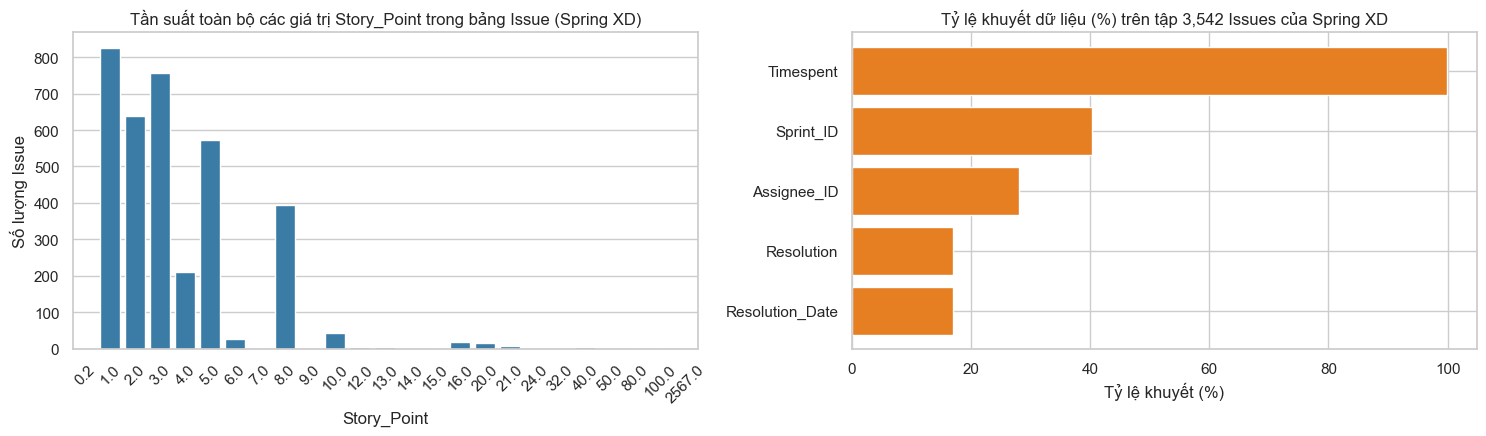

In [3]:
miss_rows = []
for col in df_xd_all.columns:
    s = df_xd[col]
    if s.dtype == object:
        cleaned_s = s.apply(strip_sql_quotes)
        n_miss = int((s.isna() | (cleaned_s == '') | (cleaned_s == 'None')).sum())
    else:
        n_miss = int(s.isna().sum())
    if n_miss > 0:
        miss_rows.append({
            'Cột có dữ liệu khuyết': col,
            'Số lượng có dữ liệu': len(df_xd) - n_miss,
            'Số lượng khuyết': n_miss,
            'Tỷ lệ khuyết (%)': round(n_miss / len(df_xd) * 100, 2)
        })
df_miss = pd.DataFrame(miss_rows).sort_values(by='Tỷ lệ khuyết (%)', ascending=False).reset_index(drop=True)
display(df_miss)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sp_counts = df_xd['Story_Point'].value_counts().sort_index()
sns.barplot(x=sp_counts.index.astype(str), y=sp_counts.values, ax=axes[0], color='#2980b9')
axes[0].set_title('Tần suất toàn bộ các giá trị Story_Point trong bảng Issue (Spring XD)')
axes[0].set_xlabel('Story_Point')
axes[0].set_ylabel('Số lượng Issue')
axes[0].tick_params(axis='x', rotation=45)

sns.barh = axes[1].barh(df_miss['Cột có dữ liệu khuyết'], df_miss['Tỷ lệ khuyết (%)'], color='#e67e22')
axes[1].set_title('Tỷ lệ khuyết dữ liệu (%) trên tập 3,542 Issues của Spring XD')
axes[1].set_xlabel('Tỷ lệ khuyết (%)')
axes[1].invert_yaxis()
plt.tight_layout()
plt.show()

### 4. Khôi phục mốc thời gian ước lượng thực tế (Real_Estimation_Date) và Initial Story Point

Trong bảng Issue của Spring XD, cột Estimation_Date bị gán cứng bằng Creation_Date (hoặc lệch -1 giờ trên 2,442 dòng) và một số Issue khi mới tạo bị người dùng điền số giả định (như 9999999, 10000000000, 1000, 444, 100, 0, NULL) trước khi đội Scrum gán điểm thật trong Change_Log. Thuật toán dưới đây khôi phục chính xác Real_Estimation_Date và Initial_Story_Point hợp lệ trong miền [0.5, 40.0].

In [4]:
sp_logs = df_cl[df_cl['Field'] == 'Story Points'].sort_values(by=['Creation_Date', 'ID']).copy()

def parse_float(val):
    if pd.isna(val):
        return np.nan
    try:
        return float(str(val).strip())
    except ValueError:
        return np.nan

sp_logs['From_Num'] = sp_logs['From_String'].apply(parse_float)
sp_logs['To_Num'] = sp_logs['To_String'].apply(parse_float)

sp_logs_grouped = {k: g for k, g in sp_logs.groupby('Issue_ID')}

real_est_dates = []
initial_sps = []
est_source_types = []

for _, row in df_xd.iterrows():
    iid = row['ID']
    c_date = str(row['Creation_Date'])
    final_sp = float(row['Story_Point'])
    
    if iid not in sp_logs_grouped:
        real_est_dates.append(c_date)
        initial_sps.append(final_sp)
        est_source_types.append('Set_At_Creation_Unchanged')
    else:
        g = sp_logs_grouped[iid]
        first_row = g.iloc[0]
        f_num = first_row['From_Num']
        
        if pd.notna(f_num) and (0.5 <= f_num <= 40.0):
            real_est_dates.append(c_date)
            initial_sps.append(f_num)
            est_source_types.append('Set_At_Creation_Later_Revised')
        else:
            valid_to = g[g['To_Num'].notna() & (g['To_Num'] >= 0.5) & (g['To_Num'] <= 40.0)]
            if len(valid_to) > 0:
                first_valid = valid_to.iloc[0]
                est_dt = max(c_date, str(first_valid['Creation_Date']))
                real_est_dates.append(est_dt)
                initial_sps.append(float(first_valid['To_Num']))
                est_source_types.append('Estimated_Later_In_ChangeLog')
            else:
                real_est_dates.append(c_date)
                initial_sps.append(final_sp)
                est_source_types.append('Unresolved_Outlier_SP')

df_xd['Real_Estimation_Date'] = real_est_dates
df_xd['Initial_Story_Point'] = initial_sps
df_xd['Estimation_Source'] = est_source_types

print("Phân bố nguồn xác định Real_Estimation_Date và Initial_Story_Point trên Spring XD:")
display(df_xd['Estimation_Source'].value_counts().reset_index())

print("\nCác trường hợp điển hình từng bị điền số giả định (Dummy Placeholder) lúc tạo và đã được khôi phục đúng:")
dummy_fixed = df_xd[df_xd['Estimation_Source'] == 'Estimated_Later_In_ChangeLog'].merge(
    sp_logs.groupby('Issue_ID').first().reset_index()[['Issue_ID', 'From_String', 'To_String', 'Creation_Date']],
    left_on='ID', right_on='Issue_ID'
)
display(dummy_fixed[['Issue_Key', 'Creation_Date_x', 'Real_Estimation_Date', 'From_String', 'Initial_Story_Point', 'Story_Point']].head(10))

Phân bố nguồn xác định Real_Estimation_Date và Initial_Story_Point trên Spring XD:


,Estimation_Source,count
0,Set_At_Creation_Unchanged,3051
1,Set_At_Creation_Later_Revised,402
2,Estimated_Later_In_ChangeLog,89



Các trường hợp điển hình từng bị điền số giả định (Dummy Placeholder) lúc tạo và đã được khôi phục đúng:


,Issue_Key,Creation_Date_x,Real_Estimation_Date,From_String,Initial_Story_Point,Story_Point
0,XD-3713,2015-11-27 13:11:27,2015-11-27 13:16:56,233,5.0,5.0
1,XD-3712,2015-11-27 04:51:43,2015-11-29 19:28:13,111,1.0,1.0
2,XD-3710,2015-11-24 13:59:57,2015-11-27 13:16:22,610,8.0,8.0
3,XD-3476,2015-09-19 03:56:45,2015-09-22 03:20:08,9999999,1.0,1.0
4,XD-3475,2015-09-19 03:32:20,2015-09-22 03:20:58,999999,1.0,1.0
5,XD-3474,2015-09-19 03:28:53,2015-09-22 03:21:04,999999,1.0,1.0
6,XD-3470,2015-09-12 19:40:25,2015-09-22 03:21:10,10000000000,1.0,1.0
7,XD-3434,2015-08-27 16:30:38,2015-08-27 16:37:56,0,3.0,3.0
8,XD-3181,2015-06-15 00:49:46,2015-07-04 12:19:38,42,8.0,8.0
9,XD-3119,2015-05-28 10:32:35,2015-05-28 10:54:09,9292,1.0,1.0


### 5. Kiểm toán toàn bộ các trường bị thay đổi sau Real_Estimation_Date trong Change_Log

Đối chiếu thời điểm thay đổi trong Change_Log với mốc Real_Estimation_Date vừa khôi phục để định lượng chính xác tỷ lệ rò rỉ tương lai của từng thuộc tính trong dự án Spring XD.

,Field,Changes_After_Est,Affected_Issues,Affected_Pct (%)
0,status,6180,2976,84.02
1,resolution,3193,2943,83.09
2,Fix Version,4446,2693,76.03
3,Rank,7569,2479,69.99
4,Workflow,2394,2394,67.59
5,Sprint,5038,2261,63.83
6,assignee,2056,1798,50.76
7,Link,1095,677,19.11
8,summary,822,607,17.14
9,Epic Link,683,581,16.40


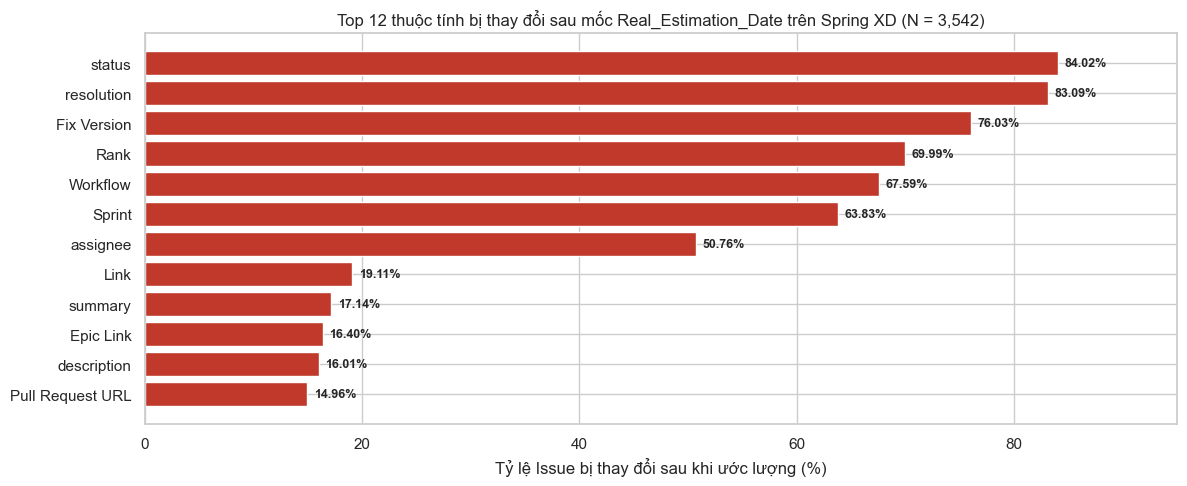

In [5]:
df_cl_m = df_cl.merge(
    df_xd[['ID', 'Issue_Key', 'Creation_Date', 'Real_Estimation_Date', 'Initial_Story_Point', 'Story_Point']],
    left_on='Issue_ID', right_on='ID', suffixes=('', '_Issue')
)

df_cl_after = df_cl_m[df_cl_m['Creation_Date'] > df_cl_m['Real_Estimation_Date']].copy()
df_cl_at_or_before = df_cl_m[df_cl_m['Creation_Date'] <= df_cl_m['Real_Estimation_Date']].copy()

leak_stats = (
    df_cl_after.groupby('Field')
    .agg(
        Changes_After_Est=('ID', 'count'),
        Affected_Issues=('Issue_ID', 'nunique')
    )
    .reset_index()
    .sort_values(by='Affected_Issues', ascending=False)
    .reset_index(drop=True)
)
leak_stats['Affected_Pct (%)'] = (leak_stats['Affected_Issues'] / len(df_xd) * 100).round(2)
display(leak_stats.head(16))

plt.figure(figsize=(12, 5))
top12 = leak_stats.head(12).sort_values(by='Affected_Pct (%)', ascending=True)
bars = plt.barh(top12['Field'], top12['Affected_Pct (%)'], color='#c0392b')
plt.title('Top 12 thuộc tính bị thay đổi sau mốc Real_Estimation_Date trên Spring XD (N = 3,542)')
plt.xlabel('Tỷ lệ Issue bị thay đổi sau khi ước lượng (%)')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.6, bar.get_y() + bar.get_height()/2, f"{w:.2f}%", va='center', fontsize=9, fontweight='bold')
plt.xlim(0, 95)
plt.tight_layout()
plt.show()

### 6. Tái dựng các đặc trưng không bị rò rỉ tại thời điểm ước lượng (Historical State Reconstruction)

Khôi phục trạng thái văn bản (Clean_Title, Clean_Description) và siêu dữ liệu (Clean_Type, Clean_Priority, Clean_Components) tại đúng thời điểm Real_Estimation_Date cho toàn bộ 3,542 công việc của dự án Spring XD.

In [6]:
def reconstruct_field_at_est(df_issues, df_after_logs, field_name_lower, final_col):
    sub = df_after_logs[df_after_logs['Field'].str.lower() == field_name_lower].copy()
    sub = sub.sort_values(by=['Creation_Date', 'ID']).groupby('Issue_ID').first().reset_index()
    first_map = dict(zip(sub['Issue_ID'], sub['From_String']))
    changed_set = set(sub['Issue_ID'])
    
    reconstructed = []
    was_modified = []
    for _, row in df_issues.iterrows():
        iid = row['ID']
        final_val = row[final_col]
        if iid in changed_set:
            raw_from = first_map[iid]
            clean_from = strip_sql_quotes(raw_from) if pd.notna(raw_from) else ""
            reconstructed.append(clean_from)
            was_modified.append(int(clean_from != final_val))
        else:
            reconstructed.append(final_val)
            was_modified.append(0)
    return reconstructed, was_modified

df_xd['Clean_Title'], df_xd['Title_Modified_After_Est'] = reconstruct_field_at_est(
    df_xd, df_cl_after, 'summary', 'Final_Title_Clean'
)
df_xd['Clean_Description'], df_xd['Desc_Modified_After_Est'] = reconstruct_field_at_est(
    df_xd, df_cl_after, 'description', 'Final_Desc_Clean'
)
df_xd['Clean_Type'], df_xd['Type_Modified_After_Est'] = reconstruct_field_at_est(
    df_xd, df_cl_after, 'issuetype', 'Type'
)
df_xd['Clean_Priority'], df_xd['Priority_Modified_After_Est'] = reconstruct_field_at_est(
    df_xd, df_cl_after, 'priority', 'Priority'
)

# Khôi phục Clean_Components tại Real_Estimation_Date
final_comp_map = df_comp.groupby('Issue_ID')['Component_Name'].apply(lambda s: set(s.dropna())).to_dict()
comp_logs_after = df_cl_after[df_cl_after['Field'] == 'Component'].sort_values(by=['Creation_Date', 'ID'], ascending=[False, False])
comp_logs_grouped = {k: g for k, g in comp_logs_after.groupby('Issue_ID')}

clean_components_list = []
final_components_list = []
comp_modified_flags = []

for _, row in df_xd.iterrows():
    iid = row['ID']
    f_set = set(final_comp_map.get(iid, set()))
    c_set = set(f_set)
    if iid in comp_logs_grouped:
        for _, crow in comp_logs_grouped[iid].iterrows():
            f_str = str(crow['From_String']).strip() if pd.notna(crow['From_String']) else ""
            t_str = str(crow['To_String']).strip() if pd.notna(crow['To_String']) else ""
            if t_str and t_str != 'None':
                c_set.discard(t_str)
            if f_str and f_str != 'None':
                c_set.add(f_str)
    clean_str = ", ".join(sorted(c_set))
    final_str = ", ".join(sorted(f_set))
    clean_components_list.append(clean_str)
    final_components_list.append(final_str)
    comp_modified_flags.append(int(clean_str != final_str))

df_xd['Clean_Components'] = clean_components_list
df_xd['Final_Components'] = final_components_list
df_xd['Component_Modified_After_Est'] = comp_modified_flags
df_xd['SP_Modified_After_Est'] = (df_xd['Initial_Story_Point'] != df_xd['Story_Point']).astype(int)

reconstruct_summary = pd.DataFrame({
    'Đặc trưng khôi phục tại Real_Estimation_Date': [
        'Clean_Title (Tiêu đề công việc)',
        'Clean_Description (Mô tả công việc)',
        'Clean_Title HOẶC Clean_Description',
        'Clean_Type (Loại Issue)',
        'Clean_Priority (Độ ưu tiên)',
        'Clean_Components (Thành phần hệ thống)',
        'Initial_Story_Point (Nhãn mục tiêu)'
    ],
    'Số Issue thực sự bị thay đổi nội dung sau ước lượng': [
        int(df_xd['Title_Modified_After_Est'].sum()),
        int(df_xd['Desc_Modified_After_Est'].sum()),
        int(((df_xd['Title_Modified_After_Est'] == 1) | (df_xd['Desc_Modified_After_Est'] == 1)).sum()),
        int(df_xd['Type_Modified_After_Est'].sum()),
        int(df_xd['Priority_Modified_After_Est'].sum()),
        int(df_xd['Component_Modified_After_Est'].sum()),
        int(df_xd['SP_Modified_After_Est'].sum())
    ],
    'Tỷ lệ thay đổi trên 3,542 Issues (%)': [
        round(df_xd['Title_Modified_After_Est'].mean()*100, 2),
        round(df_xd['Desc_Modified_After_Est'].mean()*100, 2),
        round(((df_xd['Title_Modified_After_Est'] == 1) | (df_xd['Desc_Modified_After_Est'] == 1)).mean()*100, 2),
        round(df_xd['Type_Modified_After_Est'].mean()*100, 2),
        round(df_xd['Priority_Modified_After_Est'].mean()*100, 2),
        round(df_xd['Component_Modified_After_Est'].mean()*100, 2),
        round(df_xd['SP_Modified_After_Est'].mean()*100, 2)
    ]
})
display(reconstruct_summary)

,Đặc trưng khôi phục tại Real_Estimation_Date,Số Issue thực sự bị thay đổi nội dung sau ước lượng,"Tỷ lệ thay đổi trên 3,542 Issues (%)"
0,Clean_Title (Tiêu đề công việc),603,17.02
1,Clean_Description (Mô tả công việc),566,15.98
2,Clean_Title HOẶC Clean_Description,957,27.02
3,Clean_Type (Loại Issue),259,7.31
4,Clean_Priority (Độ ưu tiên),137,3.87
5,Clean_Components (Thành phần hệ thống),265,7.48
6,Initial_Story_Point (Nhãn mục tiêu),402,11.35


### 7. Đóng gói và xuất file Cleaned Dataset (Không rò rỉ dữ liệu)

Loại bỏ triệt để toàn bộ các cột bị rò rỉ tương lai (Status, Resolution, Resolution_Date, Last_Updated, Timespent, In_Progress_Minutes, Total_Effort_Minutes, Resolution_Time_Minutes, Pull_Request_URL, Description_Code, Assignee_ID, Sprint_ID), tạo đặc trưng văn bản kết hợp Clean_Text, gắn cờ tập chuẩn và chia Chronological Split (60% Train / 20% Val / 20% Test) theo đúng thứ tự Real_Estimation_Date trước khi xuất ra file CSV.

In [7]:
df_xd['Clean_Text'] = np.where(
    df_xd['Clean_Description'].str.strip() != '',
    df_xd['Clean_Title'] + " " + df_xd['Clean_Description'],
    df_xd['Clean_Title']
)
df_xd['Clean_Title_Word_Count'] = df_xd['Clean_Title'].str.split().str.len()
df_xd['Clean_Desc_Word_Count'] = df_xd['Clean_Description'].str.split().str.len()
df_xd['Has_Clean_Description'] = (df_xd['Clean_Desc_Word_Count'] > 0).astype(int)
df_xd['Has_Clean_Component'] = (df_xd['Clean_Components'] != '').astype(int)

# Cờ kiểm tra thang điểm hợp lệ [0.5, 40.0] và cờ tập 3,526 issues tương ứng bài báo GPT2SP
df_xd['Is_Valid_Scale_SP'] = ((df_xd['Initial_Story_Point'] >= 0.5) & (df_xd['Initial_Story_Point'] <= 40.0)).astype(int)
df_xd['Issue_Num'] = df_xd['Issue_Key'].str.replace('XD-', '', regex=False).astype(int)
df_xd['Is_GPT2SP_3526_Subset'] = (df_xd['Issue_Num'] <= 3753).astype(int)

# Sắp xếp theo thời gian ước lượng thực tế (Chronological Order) để gán nhãn chia tập 60/20/20 không bị Split Leakage
df_xd = df_xd.sort_values(by=['Real_Estimation_Date', 'Creation_Date', 'ID'], ascending=[True, True, True]).reset_index(drop=True)
n_total = len(df_xd)
n_train = int(n_total * 0.6)
n_val = int(n_total * 0.8)
split_labels = ['train' if i < n_train else ('val' if i < n_val else 'test') for i in range(n_total)]
df_xd['Chronological_Split'] = split_labels

cleaned_columns = [
    'ID', 'Issue_Key', 'Project_ID',
    'Creation_Date', 'Real_Estimation_Date', 'Estimation_Source',
    'Creator_ID', 'Reporter_ID',
    'Clean_Title', 'Clean_Description', 'Clean_Text',
    'Clean_Type', 'Clean_Priority', 'Clean_Components',
    'Clean_Title_Word_Count', 'Clean_Desc_Word_Count',
    'Has_Clean_Description', 'Has_Clean_Component',
    'Title_Modified_After_Est', 'Desc_Modified_After_Est',
    'Type_Modified_After_Est', 'Priority_Modified_After_Est',
    'Component_Modified_After_Est', 'SP_Modified_After_Est',
    'Initial_Story_Point', 'Is_Valid_Scale_SP',
    'Is_GPT2SP_3526_Subset', 'Chronological_Split'
]

cleaned_dataset = df_xd[cleaned_columns].copy()

out_workspace_csv = "D:/NCKH_3/data/clean/springxd_cleaned_dataset.csv"
out_tawos_csv = "C:/tawos/springxd_cleaned_dataset.csv"
os.makedirs(os.path.dirname(out_workspace_csv), exist_ok=True)

cleaned_dataset.to_csv(out_workspace_csv, index=False, encoding='utf-8-sig')
cleaned_dataset.to_csv(out_tawos_csv, index=False, encoding='utf-8-sig')

print(f"Đã xuất thành công Cleaned Dataset ({len(cleaned_dataset):,} dòng x {len(cleaned_columns)} cột) tại:")
print(f" 1) {out_workspace_csv}")
print(f" 2) {out_tawos_csv}")

print("\nThống kê kiểm chứng chất lượng trên Cleaned Dataset:")
check_df = pd.DataFrame({
    'Chỉ số kiểm tra': [
        'Tổng số bản ghi (Rows)',
        'Số bản ghi thuộc tập chuẩn GPT2SP (XD-1 .. XD-3753)',
        'Số bản ghi có Initial_Story_Point trong miền chuẩn [0.5, 40.0]',
        'Mean Initial_Story_Point (trên miền chuẩn [0.5, 40.0])',
        'Median Initial_Story_Point (trên miền chuẩn [0.5, 40.0])',
        'Phân bổ Chronological Split (Train / Val / Test)'
    ],
    'Giá trị': [
        f"{len(cleaned_dataset):,}",
        f"{int(cleaned_dataset['Is_GPT2SP_3526_Subset'].sum()):,}",
        f"{int(cleaned_dataset['Is_Valid_Scale_SP'].sum()):,} / {len(cleaned_dataset):,}",
        f"{cleaned_dataset[cleaned_dataset['Is_Valid_Scale_SP']==1]['Initial_Story_Point'].mean():.4f}",
        f"{cleaned_dataset[cleaned_dataset['Is_Valid_Scale_SP']==1]['Initial_Story_Point'].median():.4f}",
        f"{(cleaned_dataset['Chronological_Split']=='train').sum():,} / {(cleaned_dataset['Chronological_Split']=='val').sum():,} / {(cleaned_dataset['Chronological_Split']=='test').sum():,}"
    ]
})
display(check_df)
display(cleaned_dataset.head(5))

Đã xuất thành công Cleaned Dataset (3,542 dòng x 28 cột) tại:
 1) D:/NCKH_3/data/clean/springxd_cleaned_dataset.csv
 2) C:/tawos/springxd_cleaned_dataset.csv

Thống kê kiểm chứng chất lượng trên Cleaned Dataset:


,Chỉ số kiểm tra,Giá trị
0,Tổng số bản ghi (Rows),"3,542"
1,Số bản ghi thuộc tập chuẩn GPT2SP (XD-1 .. XD-3753),"3,526"
2,"Số bản ghi có Initial_Story_Point trong miền chuẩn [0.5, 40.0]","3,536 / 3,542"
3,"Mean Initial_Story_Point (trên miền chuẩn [0.5, 40.0])",3.7055
4,"Median Initial_Story_Point (trên miền chuẩn [0.5, 40.0])",3.0000
5,Phân bổ Chronological Split (Train / Val / Test),"2,125 / 708 / 709"


,ID,Issue_Key,Project_ID,Creation_Date,Real_Estimation_Date,Estimation_Source,Creator_ID,Reporter_ID,Clean_Title,Clean_Description,Clean_Text,Clean_Type,Clean_Priority,Clean_Components,Clean_Title_Word_Count,Clean_Desc_Word_Count,Has_Clean_Description,Has_Clean_Component,Title_Modified_After_Est,Desc_Modified_After_Est,Type_Modified_After_Est,Priority_Modified_After_Est,Component_Modified_After_Est,SP_Modified_After_Est,Initial_Story_Point,Is_Valid_Scale_SP,Is_GPT2SP_3526_Subset,Chronological_Split
0,3750,XD-28,1,2013-04-17 08:48:08,2013-04-17 08:48:08,Set_At_Creation_Later_Revised,72,72,Create simple gague service,A gauge just stores a number.,Create simple gague service A gauge just stores a number.,Story,Major,Analytics,4,6,1,1,0,1,0,0,0,1,3.0,1,1,train
1,3749,XD-29,1,2013-04-17 08:49:16,2013-04-17 08:49:16,Set_At_Creation_Later_Revised,72,72,Create rich gague service,"A rich gague stores a number and also rmd, min, max.","Create rich gague service A rich gague stores a number and also rmd, min, max.",Story,Major,Analytics,4,11,1,1,1,1,0,0,0,1,3.0,1,1,train
2,3748,XD-30,1,2013-04-17 08:50:14,2013-04-17 08:50:14,Set_At_Creation_Later_Revised,72,72,Create a simple counter,A simple counters can increment/decrement a number.,Create a simple counter A simple counters can increment/decrement a number.,Story,Major,Analytics,4,7,1,1,1,1,0,0,0,1,3.0,1,1,train
3,3747,XD-31,1,2013-04-17 08:51:18,2013-04-17 08:51:18,Set_At_Creation_Later_Revised,72,72,Create field-value counters,"A field-value counter is useful for bar chart graphs, Strings on x-axis and count on y-axis. Ma...","Create field-value counters A field-value counter is useful for bar chart graphs, Strings on x-a...",Story,Major,Analytics,3,22,1,1,0,1,0,0,0,1,3.0,1,1,train
4,3769,XD-6,1,2013-04-12 06:43:18,2013-04-22 09:35:14,Estimated_Later_In_ChangeLog,72,72,Channel Registry,,Channel Registry,Story,Minor,Runtime,2,0,0,1,0,0,0,0,0,1,4.0,1,1,train
